In [9]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

In [10]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split
)

from preprocess import (
    smooth_spectra,
    vector_normalize
)

from models import get_all_models

from evaluation import evaluate_model_cv

In [11]:
spectra = pd.read_csv(
    "../data/processed_spectra.csv",
    index_col=0
)

X = spectra.drop(columns=["Label"])
y = spectra["Label"]

In [12]:
models = get_all_models()

summary = []

for name, model in models.items():

    print(f"\n{name}")
    print("-" * len(name))

    results = evaluate_model_cv(model, X, y)

    row = {"Model": name}

    for metric, (mean, std) in results.items():

        print(f"{metric:15s}: {mean:.3f} ± {std:.3f}")

        row[metric] = f"{mean:.3f} ± {std:.3f}"

    summary.append(row)


LDA
---
accuracy       : 0.911 ± 0.060
precision      : 0.932 ± 0.084
recall         : 0.896 ± 0.100
f1             : 0.908 ± 0.065
roc_auc        : 0.952 ± 0.053
specificity    : 0.927 ± 0.092

PLS-DA
------
accuracy       : 0.663 ± 0.157
precision      : 0.663 ± 0.165
recall         : 0.736 ± 0.163
f1             : 0.687 ± 0.141
roc_auc        : 0.686 ± 0.180
specificity    : 0.594 ± 0.247

Logistic Regression
-------------------
accuracy       : 0.500 ± 0.113
precision      : 0.397 ± 0.310
recall         : 0.428 ± 0.374
f1             : 0.371 ± 0.279
roc_auc        : 0.635 ± 0.163
specificity    : 0.596 ± 0.375

SVM (RBF)
---------
accuracy       : 0.523 ± 0.061
precision      : 0.492 ± 0.182
recall         : 0.862 ± 0.291
f1             : 0.606 ± 0.188
roc_auc        : 0.828 ± 0.122
specificity    : 0.196 ± 0.321

Random Forest
-------------
accuracy       : 0.933 ± 0.058
precision      : 0.948 ± 0.072
recall         : 0.922 ± 0.101
f1             : 0.930 ± 0.063
roc_auc        : 

In [13]:
results_df = pd.DataFrame(summary)

results_df

,Model,accuracy,precision,recall,f1,roc_auc,specificity
0,LDA,0.911 ± 0.060,0.932 ± 0.084,0.896 ± 0.100,0.908 ± 0.065,0.952 ± 0.053,0.927 ± 0.092
1,PLS-DA,0.663 ± 0.157,0.663 ± 0.165,0.736 ± 0.163,0.687 ± 0.141,0.686 ± 0.180,0.594 ± 0.247
2,Logistic Regression,0.500 ± 0.113,0.397 ± 0.310,0.428 ± 0.374,0.371 ± 0.279,0.635 ± 0.163,0.596 ± 0.375
3,SVM (RBF),0.523 ± 0.061,0.492 ± 0.182,0.862 ± 0.291,0.606 ± 0.188,0.828 ± 0.122,0.196 ± 0.321
4,Random Forest,0.933 ± 0.058,0.948 ± 0.072,0.922 ± 0.101,0.930 ± 0.063,0.969 ± 0.043,0.943 ± 0.079
5,XGBoost,0.893 ± 0.072,0.926 ± 0.088,0.862 ± 0.127,0.885 ± 0.084,0.931 ± 0.068,0.923 ± 0.093


In [14]:
results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [15]:
plot_df = pd.DataFrame({
    "Model": [
        "Logistic\nRegression",
        "SVM",
        "Random\nForest",
        "XGBoost"
    ],

    "Accuracy": [0.500, 0.523, 0.936, 0.897],
    "Accuracy_SD": [0.113, 0.061, 0.056, 0.076],

    "Precision": [0.397, 0.492, 0.948, 0.930],
    "Precision_SD": [0.310, 0.182, 0.070, 0.094],

    "F1": [0.371, 0.606, 0.933, 0.890],
    "F1_SD": [0.279, 0.188, 0.061, 0.086],

    "ROC-AUC": [0.636, 0.828, 0.970, 0.934],
    "ROC-AUC_SD": [0.164, 0.121, 0.042, 0.063]
})

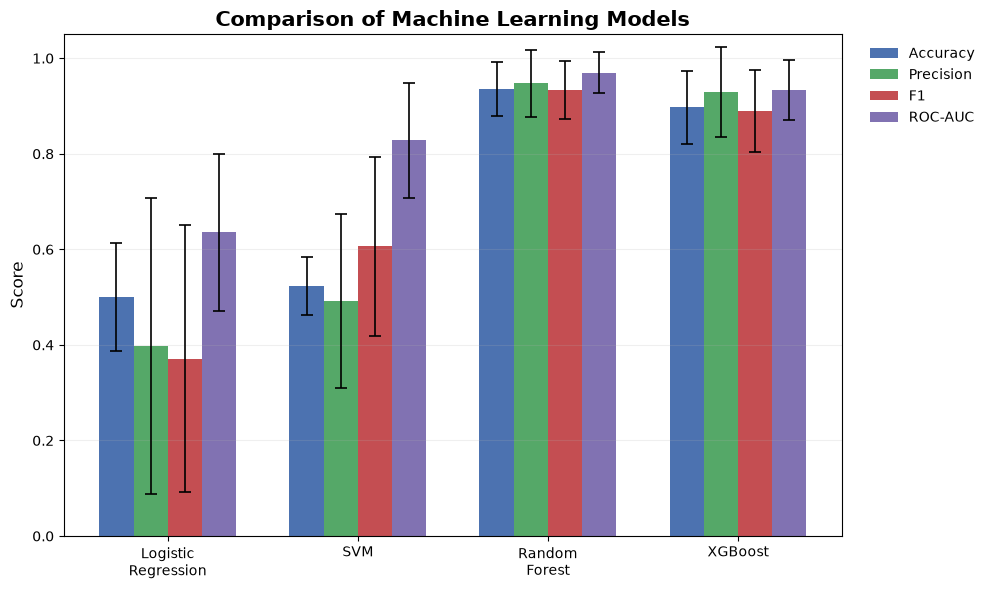

In [16]:
metrics = ["Accuracy", "Precision", "F1", "ROC-AUC"]

colors = [
    "#4C72B0",
    "#55A868",
    "#C44E52",
    "#8172B2"
]

x = np.arange(len(plot_df))
width = 0.18

fig, ax = plt.subplots(figsize=(10,6))

for i, metric in enumerate(metrics):

    ax.bar(
        x + i*width - 1.5*width,
        plot_df[metric],
        width,
        label=metric,
        color=colors[i],
        yerr=plot_df[f"{metric}_SD"],
        capsize=4,
        error_kw={
            "elinewidth":1.2,
            "capthick":1.2
        }
    )

ax.set_ylim(0,1.05)

ax.set_ylabel("Score", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"])

ax.set_title(
    "Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.2)

ax.legend(
    frameon=False,
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "../figures/Figure4_ModelComparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()